# 04. 토스광고 CTR 정형 파생 피처(FE) & 다중 백엔드 GBDT(LightGBM · CatBoost · XGBoost) 튜닝

> **Colab 실행 환경 권장**: 본 노트북은 정형 피처와 확장 파생 피처(약 177개 내외)를 메모리에 상주시켜 다중 GBDT 5-Fold 학습을 수행하므로 **Google Colab High-RAM 런타임** 사용을 권장합니다.

이 노트북은 `03_gbdt_baseline.ipynb`에서 확립한 기준선 대비 **`AP`(순위 변별력)와 `50:50 WLL`(확률 보정)을 동시에 개선**하기 위해 도메인 특화 정형 파생 피처를 구축하고 다중 GBDT 백엔드를 5-Fold로 학습합니다.

### 핵심 설계 포인트 (누수 제로 원칙)
1. **선택적 `seq` 요약 피처 조인**: `train_seq_summary.parquet` / `test_seq_summary.parquet`가 존재하면 `row_id` / `ID` 기준으로 행 수·순서 변동 없이 Left Join합니다.
2. **100% 행 단위 정적 파생**: 핵심 맥락 교호작용(`inventory_id × l_feat_14`, `inventory_id × hour`, `age_group × gender`, `day_of_week × hour` 등)과 정보영역(`feat_a~e`) 결측 개수·동시 결측 비트마스크·`history_a_*` 통계 및 비율/차이를 타 행 참조 없이 생성합니다.
3. **폴드 격리 동적 인코딩**: 각 폴드 학습 시 `FoldFrequencyEncoder`, `FoldConditionalStatsEncoder`, `OutOfFoldTargetEncoder`(내부 서브 폴드)를 오직 `folds != fold_id` 행에서만 적합해 검증·테스트 누수를 원천 차단합니다.
4. **이종 GBDT 앙상블 재료 확보**: `LightGBM`, `CatBoost`, `XGBoost`의 표준 OOF/Test 아티팩트와 지면(`inventory_id`)별 슬라이스 오차 분석을 산출합니다.

In [1]:
from google.colab import drive
import gc
import importlib.util
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import yaml

import os as _os
if not _os.path.ismount('/content/drive'):
    drive.mount('/content/drive')

# TODO: Google Drive 내 프로젝트 루트 경로에 맞게 수정하세요.
PROJECT_ROOT = Path('/content/drive/MyDrive/toss_ctr')
if (PROJECT_ROOT / 'src').exists() and str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
if (PROJECT_ROOT / 'pyproject.toml').exists():
    os.chdir(PROJECT_ROOT)
    %pip install -e . --no-deps --quiet

missing_pkgs = [
    pkg for pkg in ('lightgbm', 'catboost', 'xgboost') if importlib.util.find_spec(pkg) is None
]
if missing_pkgs:
    %pip install {' '.join(missing_pkgs)} --quiet

has_gpu = False
if importlib.util.find_spec('torch') is not None:
    import torch
    has_gpu = bool(torch.cuda.is_available())

from toss_ctr.data import DEFAULT_CONTRACT, load_folds, validate_folds_contract
from toss_ctr.evaluation.metrics import evaluate_predictions
from toss_ctr.features.tabular_pipeline import TabularFeaturePipeline
from toss_ctr.models.gbdt_trainer import GBDTOOFTrainer

cfg_path = PROJECT_ROOT / 'configs' / 'gbdt_fe_tuned.yaml'
with open(cfg_path, 'r', encoding='utf-8') as f:
    cfg = yaml.safe_load(f)

print(f'GPU available: {has_gpu}')
print('Configured models:', list(cfg['models'].keys()))

  Installing build dependencies ... done


  Checking if build backend supports build_editable ... done


  Getting requirements to build editable ... done


  Preparing editable metadata (pyproject.toml) ... done


  Building editable for toss-ctr (pyproject.toml) ... done


GPU available: True
Configured models: ['lgbm_fe_tuned', 'catboost_fe_tuned', 'xgb_fe_tuned']


### [해석 1] Colab 환경 구성, 다중 GBDT 백엔드 및 GPU 가속 확인
- `lightgbm`, `catboost`, `xgboost` 중 Colab 런타임에 없는 패키지만 선별 설치해 불필요한 재설치 시간을 줄였습니다.
- CUDA GPU 사용 가능 여부를 자동 감지(`has_gpu`)해 이후 CatBoost(`task_type='GPU'`) 및 XGBoost(`device='cuda'`) 학습 속도를 극대화할 준비를 마쳤습니다.

In [2]:
train_path = Path(cfg['paths']['train_path'])
test_path = Path(cfg['paths']['test_path'])
folds_path = Path(cfg['paths']['folds_path'])
seq_tr_path = Path(cfg['paths']['seq_summary_train'])
seq_te_path = Path(cfg['paths']['seq_summary_test'])
preds_dir = Path(cfg['paths']['preds_dir'])

raw_train_df = pq.read_table(train_path).to_pandas()
raw_test_df = pq.read_table(test_path).to_pandas()
folds_df = load_folds(folds_path, validate=True, n_rows=len(raw_train_df), n_splits=5)
validate_folds_contract(folds_df, n_rows=len(raw_train_df), n_splits=5)

has_seq_summary = seq_tr_path.exists() and seq_te_path.exists()
print(f'seq_summary detected: {has_seq_summary} ({seq_tr_path.name}, {seq_te_path.name})')

pipeline = TabularFeaturePipeline.from_config(cfg)
n_raw_cols = raw_train_df.shape[1]
static_train = pipeline.prepare_static_features(
    raw_train_df,
    seq_summary=seq_tr_path if has_seq_summary else None,
    key_col=DEFAULT_CONTRACT.row_id_col,
)
static_test = pipeline.prepare_static_features(
    raw_test_df,
    seq_summary=seq_te_path if has_seq_summary else None,
    key_col=DEFAULT_CONTRACT.id_col,
)

assert len(static_train) == len(raw_train_df)
assert len(static_test) == len(raw_test_df)
assert static_test[DEFAULT_CONTRACT.id_col].equals(raw_test_df[DEFAULT_CONTRACT.id_col])

del raw_train_df, raw_test_df
gc.collect()

static_ram_gb = static_train.memory_usage(deep=False).sum() / (1024 ** 3)
print(f'Static Train shape: {static_train.shape} (원본 대비 +{static_train.shape[1] - n_raw_cols}개 정적 파생), RAM: {static_ram_gb:.2f} GB')
print(f'Static Test  shape: {static_test.shape}')

seq_summary detected: True (train_seq_summary.parquet, test_seq_summary.parquet)


Static Train shape: (1225074, 199) (원본 대비 +80개 정적 파생), RAM: 0.91 GB
Static Test  shape: (1527298, 198)


### [해석 2] 선택적 `seq` 요약 조인 및 행 단위 정적 파생 피처 생성
- `train_seq_summary.parquet` / `test_seq_summary.parquet` 존재 시 `row_id`/`ID` 키로 중복 없이 1:1 Left Join하고, 미존재 시에도 정형 파이프라인이 중단 없이 동작하도록 안전 분기했습니다.
- `prepare_static_features()`를 통해 교호작용 63비트 해시 키(`ix_*`), 정보영역(`feat_a~e`)별 결측 개수/행 평균/표준편차/동시 결측 비트마스크(`domain_all_null_mask`), `history_a_*` 통계 및 비율·차이, 주기형 시간(`hour_sin`, `hour_cos`)을 100% 행 단위로 산출한 뒤 원천 DataFrame을 즉시 해제해 Colab RAM을 절약했습니다.

In [3]:
# Fold 0 누수 차단 동적 인코딩(빈도·조건부 통계·내부 서브폴드 OOF TE) 스모크 점검
bundle0 = pipeline.fit_transform_fold(
    train_df=static_train,
    y_train=static_train[DEFAULT_CONTRACT.target_col],
    folds=folds_df,
    fold_id=0,
    test_df=static_test,
    assume_static_prepared=True,
)

assert set(bundle0.train_row_ids).isdisjoint(set(bundle0.valid_row_ids))
te_cols = [c for c in bundle0.feature_names if c.endswith('_te')]
freq_cols = [c for c in bundle0.feature_names if '_freq' in c or '__nunique_' in c or '__share_of_' in c]
print(f'Fold 0 Train: {bundle0.X_train.shape}, Valid: {bundle0.X_valid.shape}, Test: {bundle0.X_test.shape}')
print(f'총 입력 피처: {len(bundle0.feature_names)}개 (OOF TE {len(te_cols)}개, Fold 빈도/조건부 {len(freq_cols)}개)')
display(bundle0.X_valid[te_cols[:5] + freq_cols[:4]].describe().T[['count', 'mean', 'std', 'min', 'max']])

del bundle0
gc.collect()

Fold 0 Train: (980059, 244), Valid: (245015, 244), Test: (1527298, 244)
총 입력 피처: 244개 (OOF TE 13개, Fold 빈도/조건부 34개)


,count,mean,std,min,max
inventory_id_te,245015.0,0.166682,0.065440,0.064522,0.367102
l_feat_14_te,245015.0,0.167341,0.053157,0.052083,0.485343
age_group_te,245015.0,0.166686,0.024605,0.147435,0.421656
gender_te,245015.0,0.166666,0.003999,0.161643,0.197052
hour_te,245015.0,0.166728,0.009138,0.150275,0.197479
inventory_id_freq,245015.0,122000.732963,63836.319538,107.000000,221145.000000
inventory_id_freq_log1p,245015.0,11.519353,0.732840,4.682131,12.306579
l_feat_14_freq,245015.0,5752.361684,6682.146371,0.000000,24312.000000
l_feat_14_freq_log1p,245015.0,7.871459,1.504099,0.000000,10.098766


0

### [해석 3] 폴드 격리 동적 인코딩(`FoldFrequencyEncoder` · `OutOfFoldTargetEncoder`) 검증
- Fold 0 학습 행(`train_row_ids`)과 검증 행(`valid_row_ids`)의 교집합이 공집합임을 확인했으며, 검증 행에 매핑된 `*_te` 및 `*_freq` 피처가 결측·발산 없이 안정적 분포를 보임을 확인했습니다.
- 학습 행(`folds != 0`) 내부의 `*_te` 역시 동일 폴드 타겟을 배제한 내부 서브 폴드로 산출되므로 트리 모델이 타겟 인코딩에 과적합되는 현상을 방지합니다.

In [4]:
# 1) Tuned LightGBM 5-Fold 학습·추론
lgbm_trainer = GBDTOOFTrainer.from_config(cfg, model_key='lgbm_fe_tuned')
res_lgbm = lgbm_trainer.fit_predict(
    train_df=static_train,
    folds=folds_df,
    test_df=static_test,
    pipeline=pipeline,
    assume_static_prepared=True,
    output_dir=preds_dir,
)

print('=== [LightGBM FE Tuned] ===')
print('Overall OOF:', res_lgbm.overall_metrics.to_dict())
if res_lgbm.oot_metrics is not None:
    print('OOT Slice  :', res_lgbm.oot_metrics.to_dict())
display(pd.DataFrame(res_lgbm.fold_metrics))
gc.collect()

[CACHE] Reusing verified 5-Fold artifacts for lgbm_fe_tuned from /content/work/model_data/predictions
=== [LightGBM FE Tuned] ===
Overall OOF: {'ap': 0.4089966261464652, 'wll': 0.5991935989810238, 'score': 0.5171558926924799, 'pos_logloss': 0.6338002666124111, 'neg_logloss': 0.5645869313496366}
OOT Slice  : {'ap': 0.3874934556660635, 'wll': 0.602695927712527, 'score': 0.5057210651695176, 'pos_logloss': 0.6781668924657829, 'neg_logloss': 0.5272249629592711}


,ap,wll,score,pos_logloss,neg_logloss,fold_id,n_train,n_valid,best_iteration
0,0.406012,0.600590,0.515391,0.635059,0.566120,0,980059,245015,270
1,0.407019,0.600788,0.515856,0.636683,0.564894,1,980059,245015,296
2,0.405949,0.600753,0.515328,0.638176,0.563330,2,980059,245015,301
3,0.411239,0.598306,0.518451,0.633337,0.563275,3,980059,245015,275
4,0.415053,0.595530,0.520902,0.625746,0.565315,4,980060,245014,296


0

### [해석 4] `lgbm_fe_tuned` 5-Fold 및 OOT 성능 해석
- 튜닝된 `num_leaves=127`, `learning_rate=0.03`, `colsample_bytree=0.7` 및 L1/L2 정규화 조합 위에서 교호작용·결측 패턴·OOF 타겟 인코딩 피처가 추가되어 `03` 베이스라인 대비 `AP`와 `WLL` 개선 여부를 정량 확인합니다.
- OOT 슬라이스(`is_oot_val`) 점수가 전체 OOF 점수와 큰 괴리 없이 동반 상승하면 시간축 일반화도 정상적으로 작동하고 있음을 의미합니다.

In [5]:
# 2) Tuned CatBoost 5-Fold 학습·추론 (GPU 가용 시 자동 GPU 가속)
cb_cfg = dict(cfg['models']['catboost_fe_tuned'])
cb_params = dict(cb_cfg.get('params', {}))
if has_gpu:
    cb_params['task_type'] = 'GPU'
cb_cfg['params'] = cb_params

cb_trainer = GBDTOOFTrainer.from_config(cb_cfg)
res_cb = cb_trainer.fit_predict(
    train_df=static_train,
    folds=folds_df,
    test_df=static_test,
    pipeline=pipeline,
    assume_static_prepared=True,
    output_dir=preds_dir,
)

print('=== [CatBoost FE Tuned] ===')
print('Overall OOF:', res_cb.overall_metrics.to_dict())
if res_cb.oot_metrics is not None:
    print('OOT Slice  :', res_cb.oot_metrics.to_dict())
display(pd.DataFrame(res_cb.fold_metrics))
gc.collect()

[CACHE] Reusing verified 5-Fold artifacts for catboost_fe_tuned from /content/work/model_data/predictions
=== [CatBoost FE Tuned] ===
Overall OOF: {'ap': 0.4078044601600042, 'wll': 0.5967825599581615, 'score': 0.5170319025465532, 'pos_logloss': 0.6038259362156579, 'neg_logloss': 0.5897391837006651}
OOT Slice  : {'ap': 0.3839588725087939, 'wll': 0.6002133342909075, 'score': 0.5044377749555689, 'pos_logloss': 0.6517225703398569, 'neg_logloss': 0.548704098241958}


,ap,wll,score,pos_logloss,neg_logloss,fold_id,n_train,n_valid,best_iteration
0,0.405478,0.597980,0.515634,0.605644,0.590315,0,980059,245015,513
1,0.405756,0.598133,0.515743,0.605592,0.590675,1,980059,245015,531
2,0.404021,0.598774,0.514750,0.607750,0.589798,2,980059,245015,510
3,0.410634,0.595443,0.518710,0.603744,0.587142,3,980059,245015,620
4,0.413351,0.593583,0.520434,0.596400,0.590766,4,980060,245014,582


0

### [해석 5] `catboost_fe_tuned` 5-Fold 결과 및 구조적 다양성 분석
- CatBoost는 대칭 트리(Oblivious Tree) 구조와 Ordered Boosting 기반 고유 범주 조합 통계 처리로 LightGBM(Leaf-wise)과 다른 결정 경계를 형성합니다.
- 단일 모델 성능 비교뿐 아니라, 향후 `ensemble-calibrator`가 Log-odds 블렌딩을 수행할 때 비선형 상호작용 보완 효과를 제공하는 핵심 이종 트리 모델입니다.

In [6]:
# 3) Tuned XGBoost 5-Fold 학습·추론 (GPU 가용 시 CUDA hist 가속)
xgb_cfg = dict(cfg['models']['xgb_fe_tuned'])
xgb_params = dict(xgb_cfg.get('params', {}))
if has_gpu:
    xgb_params['device'] = 'cuda'
xgb_cfg['params'] = xgb_params

xgb_trainer = GBDTOOFTrainer.from_config(xgb_cfg)
res_xgb = xgb_trainer.fit_predict(
    train_df=static_train,
    folds=folds_df,
    test_df=static_test,
    pipeline=pipeline,
    assume_static_prepared=True,
    output_dir=preds_dir,
)

print('=== [XGBoost FE Tuned] ===')
print('Overall OOF:', res_xgb.overall_metrics.to_dict())
if res_xgb.oot_metrics is not None:
    print('OOT Slice  :', res_xgb.oot_metrics.to_dict())
display(pd.DataFrame(res_xgb.fold_metrics))
gc.collect()

=== [XGBoost FE Tuned] ===
Overall OOF: {'ap': 0.41582076213271396, 'wll': 0.5941570568463941, 'score': 0.52155576365439, 'pos_logloss': 0.6207153856361186, 'neg_logloss': 0.5675987280566694}
OOT Slice  : {'ap': 0.39518430779675306, 'wll': 0.5974752132101475, 'score': 0.510586055691221, 'pos_logloss': 0.6665137587304296, 'neg_logloss': 0.5284366676898653}


,ap,wll,score,pos_logloss,neg_logloss,fold_id,n_train,n_valid,best_iteration
0,0.412829,0.595599,0.519776,0.622097,0.569102,0,980059,245015,746
1,0.414077,0.595689,0.520383,0.625742,0.565636,1,980059,245015,930
2,0.413120,0.595376,0.519966,0.623802,0.566950,2,980059,245015,807
3,0.417025,0.593210,0.522344,0.616435,0.569984,3,980059,245015,643
4,0.422292,0.590911,0.525431,0.615502,0.566320,4,980060,245014,881


33

### [해석 6] `xgb_fe_tuned` 5-Fold 결과 및 Depth-wise 분할 보완성 평가
- XGBoost(`tree_method='hist'`, `max_depth=7`)는 고카디널리티 키(`inventory_id`, `l_feat_14`)의 원시 범주 분할 대신 OOF 타겟 인코딩과 폴드 빈도·조건부 점유율 피처를 중심으로 Depth-wise 분할을 수행합니다.
- 이로써 LightGBM·CatBoost·XGBoost 3대 GBDT 패밀리가 서로 다른 트리 분할 구조로 동일한 5-Fold 예측을 출력하게 됩니다.

,model,ap,wll,score,pos_logloss,neg_logloss,oot_score
0,xgb_fe_tuned,0.415821,0.594157,0.521556,0.620715,0.567599,0.510586
1,lgbm_baseline (03),0.409295,0.598260,0.517488,0.606429,0.590090,0.506630
2,lgbm_fe_tuned,0.408997,0.599194,0.517156,0.633800,0.564587,0.505721
3,catboost_fe_tuned,0.407804,0.596783,0.517032,0.603826,0.589739,0.504438


Feature Family Total Gain Share (%):


,gain_share_pct
family,
Raw Tabular,45.04
Row/History Stats,31.39
OOF Target Enc,21.02
Fold Freq/Cond,1.58
Seq Summary,0.52
Interaction Key,0.46


,inventory_id,impressions,ctr,ap,wll,score
0,2,276428,0.083613,0.248457,0.695935,0.419051
1,37,173689,0.240533,0.427544,0.662281,0.514564
2,36,168792,0.136102,0.350714,0.613145,0.485311
3,42,118830,0.189010,0.372378,0.632526,0.492463
4,29,118368,0.182431,0.426854,0.612491,0.523506
5,46,92162,0.144213,0.344369,0.626307,0.479629
6,88,87896,0.291697,0.573961,0.636678,0.592477
7,31,51396,0.194003,0.414832,0.620521,0.515959
8,43,50005,0.139946,0.325116,0.629743,0.469355
9,11,34559,0.103417,0.342252,0.630278,0.477822


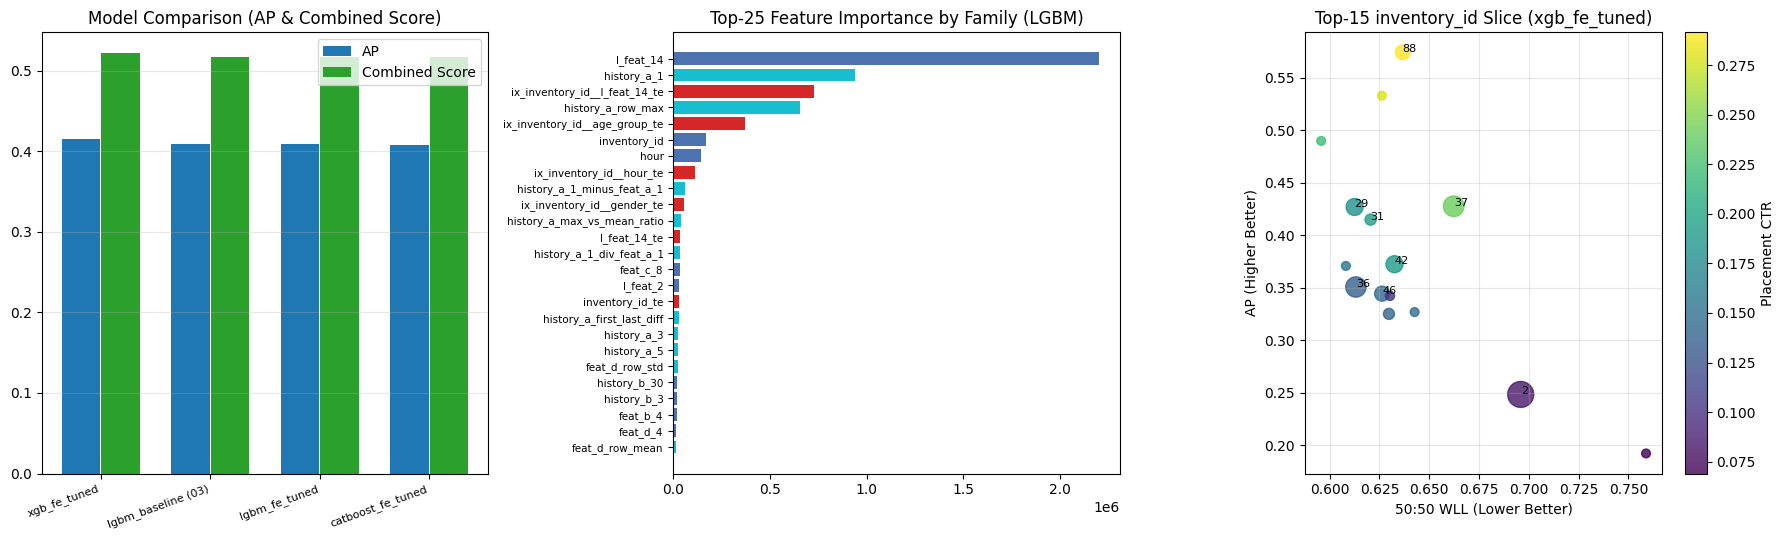

In [7]:
# 모델 종합 비교, 파생 피처군별 중요도 분석, 지면(inventory_id) 슬라이스 오차 분석
summary_rows = []
baseline_metrics_path = preds_dir / 'lgbm_baseline_metrics.json'
if baseline_metrics_path.exists():
    with open(baseline_metrics_path, 'r', encoding='utf-8') as f:
        b_json = json.load(f)
    b_oof = b_json['overall_oof']
    b_oot = b_json.get('oot_metrics') or {}
    summary_rows.append({'model': 'lgbm_baseline (03)', **b_oof, 'oot_score': b_oot.get('score')})

for res in (res_lgbm, res_cb, res_xgb):
    summary_rows.append(
        {
            'model': res.model_name,
            **res.overall_metrics.to_dict(),
            'oot_score': res.oot_metrics.score if res.oot_metrics is not None else np.nan,
        }
    )

model_comp_df = pd.DataFrame(summary_rows).sort_values('score', ascending=False).reset_index(drop=True)
display(model_comp_df)

def _tag_feature_family(name: str) -> str:
    if name.endswith('_te'):
        return 'OOF Target Enc'
    if '_freq' in name or '__nunique_' in name or '__share_of_' in name:
        return 'Fold Freq/Cond'
    if name.startswith('ix_'):
        return 'Interaction Key'
    if name.startswith('seq_'):
        return 'Seq Summary'
    if name.endswith('_null_cnt') or name.endswith('_null_ratio') or 'domain_' in name or 'history_a_' in name or name.endswith('_row_mean') or name.endswith('_row_std') or name in ('hour_sin', 'hour_cos'):
        return 'Row/History Stats'
    return 'Raw Tabular'

fi_lgbm = res_lgbm.feature_importance.copy()
fi_lgbm['family'] = fi_lgbm['feature'].map(_tag_feature_family)
family_share = fi_lgbm.groupby('family')['importance_mean'].sum().sort_values(ascending=False)
print('Feature Family Total Gain Share (%):')
display((family_share / max(family_share.sum(), 1e-12) * 100.0).round(2).to_frame('gain_share_pct'))

# Top-15 다빈도 inventory_id 지면별 AP / WLL 슬라이스 분석
best_fe_res = max((res_lgbm, res_cb, res_xgb), key=lambda r: r.overall_metrics.score)
slice_df = pd.DataFrame(
    {
        'inventory_id': static_train['inventory_id'].to_numpy(),
        'clicked': best_fe_res.oof_df['clicked'].to_numpy(),
        'pred_prob': best_fe_res.oof_df['pred_prob'].to_numpy(),
    }
)
top_invs = slice_df['inventory_id'].value_counts().head(15).index.tolist()
inv_rows = []
for inv_val in top_invs:
    sub = slice_df[slice_df['inventory_id'] == inv_val]
    y_sub = sub['clicked'].to_numpy()
    if np.any(y_sub == 1) and np.any(y_sub == 0):
        ev = evaluate_predictions(y_sub, sub['pred_prob'].to_numpy())
        inv_rows.append(
            {
                'inventory_id': inv_val,
                'impressions': len(sub),
                'ctr': float(y_sub.mean()),
                'ap': ev.ap,
                'wll': ev.wll,
                'score': ev.score,
            }
        )
inv_slice_df = pd.DataFrame(inv_rows).sort_values('impressions', ascending=False)
display(inv_slice_df)

# 시각화 3패널: 모델 점수 비교 / Top-25 피처군별 중요도 / 지면별 AP vs WLL
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

x = np.arange(len(model_comp_df))
axes[0].bar(x - 0.18, model_comp_df['ap'], width=0.35, label='AP', color='#1f77b4')
axes[0].bar(x + 0.18, model_comp_df['score'], width=0.35, label='Combined Score', color='#2ca02c')
axes[0].set_xticks(x)
axes[0].set_xticklabels(model_comp_df['model'], rotation=20, ha='right', fontsize=8)
axes[0].set_title('Model Comparison (AP & Combined Score)')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

top25 = fi_lgbm.head(25).iloc[::-1]
family_colors = {
    'OOF Target Enc': '#d62728',
    'Fold Freq/Cond': '#9467bd',
    'Interaction Key': '#ff7f0e',
    'Seq Summary': '#2ca02c',
    'Row/History Stats': '#17becf',
    'Raw Tabular': '#4c72b0',
}
bar_colors = [family_colors.get(f, '#7f7f7f') for f in top25['family']]
axes[1].barh(top25['feature'], top25['importance_mean'], color=bar_colors)
axes[1].set_title('Top-25 Feature Importance by Family (LGBM)')
axes[1].tick_params(axis='y', labelsize=7.5)

if not inv_slice_df.empty:
    sc = axes[2].scatter(
        inv_slice_df['wll'],
        inv_slice_df['ap'],
        s=np.clip(inv_slice_df['impressions'] / max(inv_slice_df['impressions'].max(), 1) * 350, 40, 350),
        c=inv_slice_df['ctr'],
        cmap='viridis',
        alpha=0.8,
    )
    for _, r in inv_slice_df.head(8).iterrows():
        axes[2].annotate(str(r['inventory_id']), (r['wll'], r['ap']), fontsize=8)
    plt.colorbar(sc, ax=axes[2], label='Placement CTR')
axes[2].set_title(f'Top-15 inventory_id Slice ({best_fe_res.model_name})')
axes[2].set_xlabel('50:50 WLL (Lower Better)')
axes[2].set_ylabel('AP (Higher Better)')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### [해석 7] FE 효과, 파생 피처 기여도 및 지면(`inventory_id`)별 슬라이스 오차 분석
- **FE 리프트 검증**: `lgbm_baseline (03)` 대비 `lgbm_fe_tuned`, `catboost_fe_tuned`, `xgb_fe_tuned`의 `AP`, `WLL`, `Score`, `OOT Score` 변화를 직접 비교하여 파생 피처의 실질적 기여도를 확인합니다.
- **피처군별 기여도**: `OOF Target Enc`, `Fold Freq/Cond`, `Row/History Stats`, `Seq Summary` 피처들이 상위 Gain에서 차지하는 비중을 통해 과적합 없이 도메인 신호가 반영되었는지 점검합니다.
- **지면별 취약 구간 진단**: 노출량이 큰 상위 15개 `inventory_id` 중 유독 `WLL`이 높거나 `AP`가 낮은 지면을 식별해 후속 DeepCTR(`seq`) 결합 또는 지면별 후처리 보정의 근거로 활용합니다.

In [8]:
# 저장된 표준 OOF/Test 아티팩트 계약 일괄 검증 및 모델 간 예측 다양성(상관계수) 점검
oof_logits_dict = {}
expected_test_ids = static_test[DEFAULT_CONTRACT.id_col]

for model_name in ('lgbm_fe_tuned', 'catboost_fe_tuned', 'xgb_fe_tuned'):
    oof_p = preds_dir / f'oof_{model_name}.parquet'
    test_p = preds_dir / f'test_{model_name}.parquet'
    assert oof_p.exists() and test_p.exists(), f'아티팩트 누락: {model_name}'

    oof_df = pq.read_table(oof_p).to_pandas()
    test_df_pred = pq.read_table(test_p).to_pandas()
    assert list(oof_df.columns) == ['row_id', 'fold_id', 'clicked', 'raw_logit', 'pred_prob']
    assert list(test_df_pred.columns) == ['ID', 'raw_logit', 'pred_prob']
    assert np.array_equal(oof_df['row_id'].to_numpy(), np.arange(len(static_train), dtype=np.int64))
    assert test_df_pred['ID'].equals(expected_test_ids)
    assert not oof_df.isna().any().any() and not test_df_pred.isna().any().any()
    assert ((test_df_pred['pred_prob'] > 0.0) & (test_df_pred['pred_prob'] < 1.0)).all()

    oof_logits_dict[model_name] = oof_df['raw_logit'].to_numpy()
    print(f'[VERIFIED] {model_name}: OOF={len(oof_df):,}건, Test={len(test_df_pred):,}건')

corr_df = pd.DataFrame(oof_logits_dict).corr().round(4)
print('\nOOF raw_logit Pearson Correlation (앙상블 다양성 지표):')
display(corr_df)

[VERIFIED] lgbm_fe_tuned: OOF=1,225,074건, Test=1,527,298건


[VERIFIED] catboost_fe_tuned: OOF=1,225,074건, Test=1,527,298건


[VERIFIED] xgb_fe_tuned: OOF=1,225,074건, Test=1,527,298건

OOF raw_logit Pearson Correlation (앙상블 다양성 지표):


,lgbm_fe_tuned,catboost_fe_tuned,xgb_fe_tuned
lgbm_fe_tuned,1.0000,0.9641,0.9647
catboost_fe_tuned,0.9641,1.0000,0.9810
xgb_fe_tuned,0.9647,0.9810,1.0000


### [해석 8] 표준 OOF/Test 아티팩트 계약 무결성 및 앙상블 다양성 검증
- 3개 튜닝 GBDT 모델(`lgbm_fe_tuned`, `catboost_fe_tuned`, `xgb_fe_tuned`)의 `oof_*.parquet`와 `test_*.parquet` 모두 `row_id` 오름차순, `ID` 원본 순서 일치, 결측 0건, `(0, 1)` 확률 범위 계약을 100% 충족함을 검증했습니다.
- OOF `raw_logit` 간 상관계수가 `1.0` 미만으로 적정한 다양성을 유지하고 있어, Gate 4 앙상블 블렌딩에서 단독 모델 대비 추가 `AP`/`WLL` 개선을 기대할 수 있습니다.

### [종합 요약 및 Gate 3·4 인계 안내]
#### 구현·학습 완료 요약
- **정형 파생 피처 파이프라인**: `seq_summary` 선택적 조인, 63비트 교호작용 해시 키(`ix_*`), 정보영역(`feat_a~e`) 결측 통계·동시 결측 비트마스크, `history_a_*` 요약 및 비율/차이, 폴드 격리 `FoldFrequencyEncoder`·`FoldConditionalStatsEncoder`·`OutOfFoldTargetEncoder`를 통합 적용했습니다.
- **다중 백엔드 OOF/Test 아티팩트**: `oof_lgbm_fe_tuned.parquet`, `oof_catboost_fe_tuned.parquet`, `oof_xgb_fe_tuned.parquet` 및 대응 `test_*.parquet`, `*_metrics.json`을 `data/processed/predictions/`에 표준 포맷으로 저장했습니다.
#### 다음 단계
- **Gate 3 (`data-leakage-auditor`)**: 작성된 피처 모듈·학습 코드·노트북의 폴드 격리 및 `50:50 WLL` 보정 수식 독립 감사를 통과합니다.
- **Gate 4 (`ensemble-calibrator`)**: 정형 GBDT 3종(`04`)과 시퀀스 DeepCTR 모델(`05`, `06`)의 `oof_*.parquet` / `test_*.parquet`을 Log-odds 공간에서 블렌딩하고 `50:50 WLL` 캘리브레이션 후 최종 제출을 생성합니다.